# ReactionT5v2: Forward Reaction Prediction Evaluation

## 1. Setup and Model Loading

In [19]:
import sys
from pathlib import Path

import pandas as pd
import torch
from transformers import AutoTokenizer

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

from rdkit import RDLogger
RDLogger.DisableLog("rdApp.error")

PyTorch version: 2.14.0
Device: cpu


In [2]:
PROJECT_ROOT = Path.cwd().parent
REACTIONT5_DIR = PROJECT_ROOT / "external" / "ReactionT5v2"
TASK_FORWARD_DIR = REACTIONT5_DIR / "task_forward"

sys.path.insert(0, str(REACTIONT5_DIR))
sys.path.insert(0, str(TASK_FORWARD_DIR))

print("Project root:", PROJECT_ROOT)
print("ReactionT5 directory:", REACTIONT5_DIR)
print("Task forward directory:", TASK_FORWARD_DIR)
print("ReactionT5 found:", REACTIONT5_DIR.exists())
print("Task forward found:", TASK_FORWARD_DIR.exists())

Project root: /Users/tanyagoel101/Downloads/data-discovery
ReactionT5 directory: /Users/tanyagoel101/Downloads/data-discovery/external/ReactionT5v2
Task forward directory: /Users/tanyagoel101/Downloads/data-discovery/external/ReactionT5v2/task_forward
ReactionT5 found: True
Task forward found: True


In [3]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

MODEL_NAME = "sagawa/ReactionT5v2-forward"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("ReactionT5 loaded successfully!")
print("Device:", device)

/Users/tanyagoel101/miniconda3/envs/reactiont5/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


ReactionT5 loaded successfully!
Device: cpu


/Users/tanyagoel101/miniconda3/envs/reactiont5/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [4]:
def predict_reaction(input_text, num_predictions=5):
    # Tokenize the preprocessed ReactionT5 input
    inputs = tokenizer(
        input_text,
        return_tensors="pt",
        max_length=400,
        truncation=True
    ).to(device)

    # Generate ranked predictions
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            num_beams=num_predictions,
            num_return_sequences=num_predictions,
            return_dict_in_generate=True,
            output_scores=True,
            max_length=400
        )

    # Convert token IDs back into predicted product strings
    predictions = tokenizer.batch_decode(
        outputs.sequences,
        skip_special_tokens=True
    )

    # Generation scores
    scores = outputs.sequences_scores.cpu().tolist()

    return list(zip(predictions, scores))

## 2. Dataset Loading and Preprocessing

In [5]:
import pandas as pd
import os

print("Working directory:", os.getcwd())

# Load the test dataset
test_df = pd.read_csv("../data/ord_100_reactions.csv")

print("Dataset shape:", test_df.shape)
display(test_df.head())

Working directory: /Users/tanyagoel101/Downloads/data-discovery/notebooks
Dataset shape: (100, 3)


,reaction_id,reaction_smiles,source_shard
0,ord-a39736b37fbe484196bbf8bf6c949a4d,[F:1][C:2]1[CH:16]=[CH:15][C:5]2[C:6]([CH:9]3[...,11
1,ord-ff90e493aecd4338bb1012ca611b69cd,[CH2:28]([CH3:29])[O:30][P:31]([O:32][CH2:33][...,e7
2,ord-eed4a220b9c349bfb0cecdd2299756a5,[CH3:1][C:2]1[CH:10]=[CH:9][C:8]([N+:11]([O-])...,11
3,ord-dc519f42994b4ba2a037e579a6093a51,Cc1ccc(Oc2ccc(N)cc2)cc1.O=C(O)Cc1ccc(C(F)(F)F)...,47
4,ord-7f5e07f90753423397da825351d767bd,[Br:1][C:2]1[CH:6]=[CH:5][S:4][C:3]=1[C:7]([C:...,11


In [6]:
# Split each reaction into reactants, reagents, and products
test_df[["reactants", "reagents", "expected_product"]] = (
    test_df["reaction_smiles"].str.split(">", n=2, expand=True)
)

# Display the separated components
display(test_df[[
    "reactants",
    "reagents",
    "expected_product"
]].head())

,reactants,reagents,expected_product
0,[F:1][C:2]1[CH:16]=[CH:15][C:5]2[C:6]([CH:9]3[...,C(#N)C.C(O)C,[C:38]([OH:45])(=[O:44])/[CH:39]=[CH:40]/[C:41...
1,[CH2:28]([CH3:29])[O:30][P:31]([O:32][CH2:33][...,,[Cl:1][CH2:2][CH2:3][N:4]([c:5]1[c:6]([CH2:11]...
2,[CH3:1][C:2]1[CH:10]=[CH:9][C:8]([N+:11]([O-])...,,[CH3:1][C:2]1[CH:10]=[CH:9][C:8]([NH2:11])=[CH...
3,Cc1ccc(Oc2ccc(N)cc2)cc1.O=C(O)Cc1ccc(C(F)(F)F)...,,Cc1ccc(Oc2ccc(NC(=O)Cc3ccc(C(F)(F)F)cc3)cc2)cc1
4,[Br:1][C:2]1[CH:6]=[CH:5][S:4][C:3]=1[C:7]([C:...,C1(C)C=CC=CC=1.O,[Br:1][C:2]1[CH:6]=[CH:5][S:4][C:3]=1[C:7]([C:...


In [7]:
from rdkit import Chem
import pandas as pd

def clean_smiles(smiles):
    if pd.isna(smiles):
        return None

    # Remove CXSMILES annotations before cleaning whitespace
    smiles = smiles.split("|")[0].strip()

    # Remove spaces introduced by model generation
    smiles = "".join(smiles.split())

    if not smiles:
        return None

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # Remove atom-mapping numbers
    for atom in mol.GetAtoms():
        atom.SetAtomMapNum(0)

    return Chem.MolToSmiles(mol, canonical=True)


# Clean each reaction component
for col in ["reactants", "reagents", "expected_product"]:
    test_df[col + "_clean"] = test_df[col].apply(clean_smiles)

display(test_df[[
    "reactants_clean",
    "reagents_clean",
    "expected_product_clean"
]].head())


[02:27:26] WARNING: not removing hydrogen atom without neighbors
[02:27:26] WARNING: not removing hydrogen atom without neighbors
[02:27:26] WARNING: not removing hydrogen atom without neighbors
[02:27:26] WARNING: not removing hydrogen atom without neighbors


,reactants_clean,reagents_clean,expected_product_clean
0,CC(=O)Nc1cccc(OCCCBr)c1.Fc1ccc2c(C3CCNCC3)noc2...,CC#N.CCO,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...
1,CCOP(=O)(OCC)C(CCCN)P(=O)(OCC)OCC.O=C(O)CCCc1c...,None,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...
2,Cc1ccc([N+](=O)[O-])cc1C(=O)O.Cl.[Sn],None,Cc1ccc(N)cc1C(=O)O
3,CCN(C(C)C)C(C)C.CCN=C=NCCCN(C)C.CN(C)C=O.Cc1cc...,None,Cc1ccc(Oc2ccc(NC(=O)Cc3ccc(C(F)(F)F)cc3)cc2)cc1
4,COc1ccc(C(=O)c2sccc2Br)cc1.Cl.Cl.NO.c1ccncc1,Cc1ccccc1.O,COc1ccc(C(=NO)c2sccc2Br)cc1


In [8]:

from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

# Morgan fingerprint generator
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def tanimoto_similarity(predicted, expected):
    if predicted is None or expected is None:
        return None

    pred_mol = Chem.MolFromSmiles(predicted)
    true_mol = Chem.MolFromSmiles(expected)

    if pred_mol is None or true_mol is None:
        return None

    pred_fp = morgan_generator.GetFingerprint(pred_mol)
    true_fp = morgan_generator.GetFingerprint(true_mol)

    return DataStructs.TanimotoSimilarity(pred_fp, true_fp)

In [9]:

test_df["model_input"] = (
    "REACTANT:" + test_df["reactants_clean"].fillna("")
    + "REAGENT:" + test_df["reagents_clean"].fillna("")
)

print(test_df["model_input"].iloc[0])


REACTANT:CC(=O)Nc1cccc(OCCCBr)c1.Fc1ccc2c(C3CCNCC3)noc2c1.O=C(O)/C=C/C(=O)O.O=C([O-])[O-].[K+].[K+]REAGENT:CC#N.CCO


## 3. ReactionT5 Prediction Generation

In [10]:
from tqdm.auto import tqdm

all_predictions = []

for i, row in tqdm(test_df.iterrows(), total=len(test_df)):
    reaction_input = row["model_input"]
    expected = row["expected_product_clean"]

    predictions = predict_reaction(
        reaction_input,
        num_predictions=5
    )

    for rank, (prediction, score) in enumerate(predictions, start=1):
        cleaned_prediction = clean_smiles(prediction)

        correct = (
            cleaned_prediction is not None
            and expected is not None
            and cleaned_prediction == expected
        )

        all_predictions.append({
            "reaction_id": row["reaction_id"],
            "rank": rank,
            "raw_prediction": prediction,
            "predicted_product": cleaned_prediction,
            "expected_product": expected,
            "score": score,
            "valid_smiles": cleaned_prediction is not None,
            "correct": correct,
            "tanimoto": tanimoto_similarity(
                cleaned_prediction, expected
            )
        })

results_100 = pd.DataFrame(all_predictions)

print("Total predictions:", len(results_100))
display(results_100.head(10))

  0%|          | 0/100 [00:00<?, ?it/s]

[02:27:36] SMILES Parse Error: syntax error while parsing: CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1.CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1H.O=C(O)/C=C/C(=O)O
[02:27:36] SMILES Parse Error: check for mistakes around position 96:
[02:27:36] oc4cc(F)ccc34)CC2)c1H.O=C(O)/C=C/C(=O)O
[02:27:36] ~~~~~~~~~~~~~~~~~~~~^
[02:27:36] SMILES Parse Error: Failed parsing SMILES 'CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1.CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1H.O=C(O)/C=C/C(=O)O' for input: 'CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1.CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1H.O=C(O)/C=C/C(=O)O'
[02:27:36] SMILES Parse Error: syntax error while parsing: CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1.CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c1Ca.O=C(O)/C=C/C(=O)O
[02:27:36] SMILES Parse Error: check for mistakes around position 97:
[02:27:36] c4cc(F)ccc34)CC2)c1Ca.O=C(O)/C=C/C(=O)O
[02:27:36] ~~~~~~~~~~~~~~~~~~~~^
[02:27:36] SMILES Parse Error: Failed parsing

Total predictions: 500


,reaction_id,rank,raw_prediction,predicted_product,expected_product,score,valid_smiles,correct,tanimoto
0,ord-a39736b37fbe484196bbf8bf6c949a4d,1,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,0.000000,True,True,1.000000
1,ord-a39736b37fbe484196bbf8bf6c949a4d,2,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,None,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,-0.200334,False,False,NaN
2,ord-a39736b37fbe484196bbf8bf6c949a4d,3,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,-0.206471,True,False,0.985294
3,ord-a39736b37fbe484196bbf8bf6c949a4d,4,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,-0.214595,True,False,0.917808
4,ord-a39736b37fbe484196bbf8bf6c949a4d,5,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,None,CC(=O)Nc1cccc(OCCCN2CCC(c3noc4cc(F)ccc34)CC2)c...,-0.223977,False,False,NaN
5,ord-ff90e493aecd4338bb1012ca611b69cd,1,CCOP (=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl )CC...,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...,-0.000004,True,True,1.000000
6,ord-ff90e493aecd4338bb1012ca611b69cd,2,CCOP (=O)(OCC)C(CCCN)P (=O)(OCC)OCC. O=C(O)CCC...,CCOP(=O)(OCC)C(CCCN)P(=O)(OCC)OCC.O=C(O)CCCc1c...,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...,-0.157870,True,False,0.721311
7,ord-ff90e493aecd4338bb1012ca611b69cd,3,CCOP (=O)(OCC)C(CCCN(CCCl )c1ccccc1CCCC(=O)O)P...,CCOP(=O)(OCC)C(CCCN(CCCl)c1ccccc1CCCC(=O)O)P(=...,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...,-0.256656,True,False,0.745763
8,ord-ff90e493aecd4338bb1012ca611b69cd,4,CCOP (=O)(OCC)C(CCCN(CCCl )c1ccccc1CCCC(=O)N1C...,CCOP(=O)(OCC)C(CCCN(CCCl)c1ccccc1CCCC(=O)N1CCC...,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...,-0.265707,True,False,0.611111
9,ord-ff90e493aecd4338bb1012ca611b69cd,5,CCOP (=O)(OCC)C(CCCNCCCC(=O)CCCc1ccccc1N(CCCl ...,CCOP(=O)(OCC)C(CCCNCCCC(=O)CCCc1ccccc1N(CCCl)C...,CCOP(=O)(OCC)C(CCCNC(=O)CCCc1ccccc1N(CCCl)CCCl...,-0.289668,True,False,0.783333


## 4. Model Evaluation

In [11]:
# Calculate overall accuracy metrics

# Select only the highest-ranked prediction per reaction
top1_df = results_100[results_100["rank"] == 1].copy()

# Top-1 accuracy
top1_accuracy = top1_df["correct"].mean() * 100

# Top-5 accuracy: at least one correct prediction per reaction
top5_accuracy = (
    results_100.groupby("reaction_id")["correct"].any().mean() * 100
)

# Valid SMILES rate across all 500 predictions
valid_smiles_rate = results_100["valid_smiles"].mean() * 100

# Average Tanimoto similarity for rank-1 predictions
avg_tanimoto = top1_df["tanimoto"].mean()

print(f"Top-1 Accuracy: {top1_accuracy:.2f}%")
print(f"Top-5 Accuracy: {top5_accuracy:.2f}%")
print(f"Valid SMILES Rate: {valid_smiles_rate:.2f}%")
print(f"Average Rank-1 Tanimoto: {avg_tanimoto:.4f}")
print(f"Rank-1 predictions with valid Tanimoto: {top1_df['tanimoto'].notna().sum()}/100")

Top-1 Accuracy: 91.00%
Top-5 Accuracy: 93.00%
Valid SMILES Rate: 87.20%
Average Rank-1 Tanimoto: 0.9666
Rank-1 predictions with valid Tanimoto: 99/100


In [12]:

# Generate chirality-aware Morgan fingerprints
chiral_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=True
)

def chiral_tanimoto(predicted, expected):
    if predicted is None or expected is None:
        return None

    pred_mol = Chem.MolFromSmiles(predicted)
    true_mol = Chem.MolFromSmiles(expected)

    if pred_mol is None or true_mol is None:
        return None

    pred_fp = chiral_generator.GetFingerprint(pred_mol)
    true_fp = chiral_generator.GetFingerprint(true_mol)

    return DataStructs.TanimotoSimilarity(pred_fp, true_fp)

# Calculate chirality-aware similarity for all 500 predictions
results_100["chiral_tanimoto"] = results_100.apply(
    lambda row: chiral_tanimoto(
        row["predicted_product"],
        row["expected_product"]
    ),
    axis=1
)

# Compare the two metrics for rank-1 predictions
top1_df = results_100[results_100["rank"] == 1].copy()

print("Average standard Tanimoto:",
      round(top1_df["tanimoto"].mean(), 4))

print("Average chirality-aware Tanimoto:",
      round(top1_df["chiral_tanimoto"].mean(), 4))

display(top1_df[[
    "reaction_id",
    "correct",
    "tanimoto",
    "chiral_tanimoto"
]].head(10))


Average standard Tanimoto: 0.9666
Average chirality-aware Tanimoto: 0.9652


,reaction_id,correct,tanimoto,chiral_tanimoto
0,ord-a39736b37fbe484196bbf8bf6c949a4d,True,1.000000,1.000000
5,ord-ff90e493aecd4338bb1012ca611b69cd,True,1.000000,1.000000
10,ord-eed4a220b9c349bfb0cecdd2299756a5,False,0.958333,0.958333
15,ord-dc519f42994b4ba2a037e579a6093a51,True,1.000000,1.000000
20,ord-7f5e07f90753423397da825351d767bd,True,1.000000,1.000000
25,ord-7ac2012943d74578925c175b78f86238,True,1.000000,1.000000
30,ord-c229ddbac6a646278bbe75bdb716d904,True,1.000000,1.000000
35,ord-dd0fd7527b484e9eb453ab57d7927789,True,1.000000,1.000000
40,ord-75298042fa44476596721fb190ccd9a1,True,1.000000,1.000000
45,ord-e0f1cbd004a54f68b537b4ea56ca5627,True,1.000000,1.000000


## 5. Model Score and Similarity Analysis

Pearson correlation: 0.2370
Spearman correlation: 0.3503


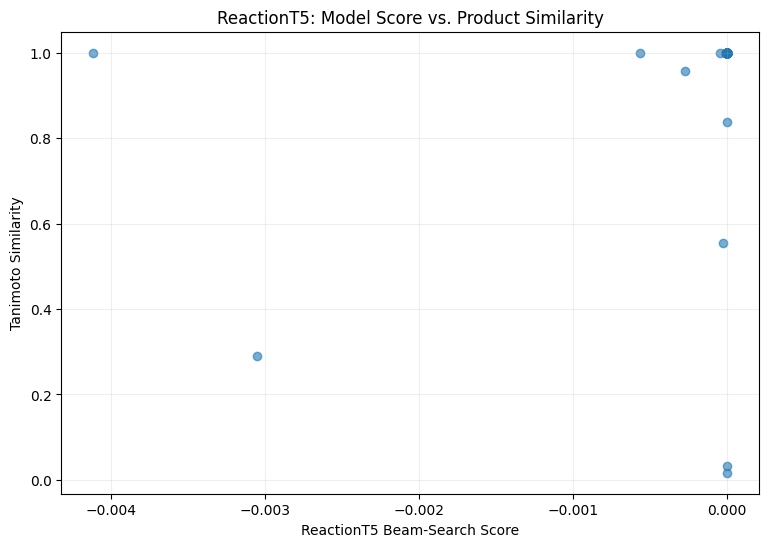

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

# Only rank-1 predictions with valid similarity scores
correlation_df = top1_df.dropna(
    subset=["score", "tanimoto"]
).copy()

pearson_corr = correlation_df["score"].corr(
    correlation_df["tanimoto"],
    method="pearson"
)

spearman_corr = correlation_df["score"].corr(
    correlation_df["tanimoto"],
    method="spearman"
)

print(f"Pearson correlation: {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

# Plot score versus chemical similarity
plt.figure(figsize=(9, 6))

plt.scatter(
    correlation_df["score"],
    correlation_df["tanimoto"],
    alpha=0.6
)

plt.xlabel("ReactionT5 Beam-Search Score")
plt.ylabel("Tanimoto Similarity")
plt.title("ReactionT5: Model Score vs. Product Similarity")

plt.grid(alpha=0.2)
plt.show()

In [14]:

# Examine the nine incorrect rank-1 predictions
incorrect_top1 = top1_df[
    ~top1_df["correct"]
].copy()

incorrect_top1 = incorrect_top1.sort_values(
    "tanimoto",
    ascending=True,
    na_position="last"
)

print("Number of incorrect rank-1 predictions:", len(incorrect_top1))

display(incorrect_top1[[
    "reaction_id",
    "predicted_product",
    "expected_product",
    "score",
    "valid_smiles",
    "tanimoto"
]])


Number of incorrect rank-1 predictions: 9


,reaction_id,predicted_product,expected_product,score,valid_smiles,tanimoto
415,ord-6d3e8725140c408695b82fbf3933c493,N,CC1(c2cccc(NS(C)(=O)=O)c2)C2CN(C(=O)CCc3c[nH]c...,-3.973643e-08,True,0.016667
240,ord-0770370d7f614523ad29a6beba17d3d4,N,CN(C)Cc1cn(-c2ccc(N)cc2)nn1.N,-1.311300e-06,True,0.032258
490,ord-382a36eec7a547b1b21f410352eb9872,CC1C(=O)CC1c1ccccc1,CC1CNC(=O)c2ccccc21,-3.048284e-03,True,0.289474
255,ord-a7c18fd83270469a967d36d2fe56f14e,COc1ccc2c(c1)CC(C)(C)CC2=O,CCOC(=O)C(C(=O)OCC)C(C)(C)Cc1cccc(OC)c1.COc1cc...,-2.432156e-05,True,0.555556
65,ord-37f43d139b5a4a3782d8f9fad915a9aa,C=C=C(C(=O)OCc1ccc([N+](=O)[O-])cc1)N1C(=O)[C@...,C=C=C(C(=O)OCc1ccc([N+](=O)[O-])cc1)N1C(=O)[C@...,-1.828741e-06,True,0.837500
10,ord-eed4a220b9c349bfb0cecdd2299756a5,Cc1ccc(N)cc1C(=O)O.Cl,Cc1ccc(N)cc1C(=O)O,-2.734324e-04,True,0.958333
245,ord-8e6edc6bc58d4625ac0eebe56599e4d5,C[C@H]1CC[C@H](N(C(=O)Nc2ncc(SCCC(=O)O)s2)C2CC...,C[C@@H]1CC[C@@H](N(C(=O)Nc2ncc(SCCC(=O)O)s2)C2...,0.000000e+00,True,1.000000
360,ord-0c14bfc6aeef48d6bdecfcfe838e6f7e,C/C(=C\c1csc(C)n1)[C@@H]1C/C=C\CCC[C@H](C)[C@H...,C/C(=C\c1csc(C)n1)[C@@H]1CC=CCCC[C@H](C)[C@H](...,-1.009769e-07,True,1.000000
440,ord-fe87b465c3e7466bb9912a0ae211d039,None,[Li][CH]1C=Cc2ccccc21,-3.875849e-02,False,NaN


In [15]:

# Inspect predictions with perfect Tanimoto but incorrect exact match

special_cases = results_100[
    (results_100["tanimoto"] == 1.0)
    & (~results_100["correct"])
].copy()

for _, row in special_cases.iterrows():
    pred = Chem.MolFromSmiles(row["predicted_product"])
    true = Chem.MolFromSmiles(row["expected_product"])

    print("\nReaction:", row["reaction_id"])
    print("Rank:", row["rank"])

    print("Predicted:", row["predicted_product"])
    print("Expected:", row["expected_product"])

    print("Match without stereochemistry:",
          Chem.MolToSmiles(pred, isomericSmiles=False)
          == Chem.MolToSmiles(true, isomericSmiles=False))

    print("Match with stereochemistry:",
          Chem.MolToSmiles(pred, isomericSmiles=True)
          == Chem.MolToSmiles(true, isomericSmiles=True))



Reaction: ord-7f5e07f90753423397da825351d767bd
Rank: 3
Predicted: COc1ccc(/C(=N\O)c2sccc2Br)cc1
Expected: COc1ccc(C(=NO)c2sccc2Br)cc1
Match without stereochemistry: True
Match with stereochemistry: False

Reaction: ord-7f5e07f90753423397da825351d767bd
Rank: 4
Predicted: COc1ccc(/C(=N/O)c2sccc2Br)cc1
Expected: COc1ccc(C(=NO)c2sccc2Br)cc1
Match without stereochemistry: True
Match with stereochemistry: False

Reaction: ord-75298042fa44476596721fb190ccd9a1
Rank: 2
Predicted: CN(C(=O)OC(C)(C)C)/C(=N/OCCN)NC(=O)OC(C)(C)C
Expected: CN(C(=O)OC(C)(C)C)C(=NOCCN)NC(=O)OC(C)(C)C
Match without stereochemistry: True
Match with stereochemistry: False

Reaction: ord-05fe39220067459285c6760684758e9b
Rank: 2
Predicted: COc1ccc(OC)c(C(=O)/C=C/c2c[nH]c3ccccc23)c1
Expected: COc1ccc(OC)c(C(=O)C=Cc2c[nH]c3ccccc23)c1
Match without stereochemistry: True
Match with stereochemistry: False

Reaction: ord-aa505093bb954ccb9d8c7b2961d0be5c
Rank: 4
Predicted: Cc1cccc(-c2nc(CCOc3ccc(/C=C/C=C4/OC(=O)NC4=O)cc3)c(C)o2)c

## 6. Error Analysis

In [16]:

# Compare standard and chirality-aware similarity
# for incorrect rank-1 predictions

incorrect_top1 = top1_df[
    ~top1_df["correct"]
].copy()

incorrect_top1["similarity_difference"] = (
    incorrect_top1["tanimoto"]
    - incorrect_top1["chiral_tanimoto"]
)

display(incorrect_top1[[
    "reaction_id",
    "tanimoto",
    "chiral_tanimoto",
    "similarity_difference"
]].sort_values("similarity_difference", ascending=False))


,reaction_id,tanimoto,chiral_tanimoto,similarity_difference
360,ord-0c14bfc6aeef48d6bdecfcfe838e6f7e,1.000000,0.863636,0.136364
10,ord-eed4a220b9c349bfb0cecdd2299756a5,0.958333,0.958333,0.000000
65,ord-37f43d139b5a4a3782d8f9fad915a9aa,0.837500,0.837500,0.000000
240,ord-0770370d7f614523ad29a6beba17d3d4,0.032258,0.032258,0.000000
245,ord-8e6edc6bc58d4625ac0eebe56599e4d5,1.000000,1.000000,0.000000
255,ord-a7c18fd83270469a967d36d2fe56f14e,0.555556,0.555556,0.000000
415,ord-6d3e8725140c408695b82fbf3933c493,0.016667,0.016667,0.000000
490,ord-382a36eec7a547b1b21f410352eb9872,0.289474,0.289474,0.000000
440,ord-fe87b465c3e7466bb9912a0ae211d039,NaN,NaN,NaN


## 7. Export Results

In [17]:
from pathlib import Path
import pandas as pd

# Create output directory
output_dir = Path("../data/reactiont5_evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

# Save all 500 predictions
results_100.to_csv(
    output_dir / "reactiont5_predictions.csv",
    index=False
)

# Save evaluation metrics
summary_df = pd.DataFrame([{
    "num_reactions": top1_df["reaction_id"].nunique(),
    "top1_accuracy": top1_df["correct"].mean(),
    "top5_accuracy": results_100.groupby("reaction_id")["correct"].any().mean(),
    "valid_smiles_rate": results_100["valid_smiles"].mean(),
    "average_rank1_tanimoto": top1_df["tanimoto"].mean(),
    "average_rank1_chiral_tanimoto": top1_df["chiral_tanimoto"].mean(),
    "pearson_correlation": pearson_corr,
    "spearman_correlation": spearman_corr
}])

summary_df.to_csv(
    output_dir / "reactiont5_summary.csv",
    index=False
)

display(summary_df)

print("Saved files to:", output_dir.resolve())

,num_reactions,top1_accuracy,top5_accuracy,valid_smiles_rate,average_rank1_tanimoto,average_rank1_chiral_tanimoto,pearson_correlation,spearman_correlation
0,100,0.91,0.93,0.872,0.966564,0.965186,0.237038,0.350314


Saved files to: /Users/tanyagoel101/Downloads/data-discovery/data/reactiont5_evaluation


In [18]:
print(list(output_dir.iterdir()))

[PosixPath('../data/reactiont5_evaluation/reactiont5_summary.csv'), PosixPath('../data/reactiont5_evaluation/reactiont5_predictions.csv')]
